## PPGCC: COMPUTACAO NATURAL, Prof. Gisele; Autor: Marco Túlio S. da Mata; UFMG

# Ant Colony Optimization para Roteamento Global em Projetos VLSI

Este notebook é a continuação de *Simulated Annealing para Posicionamento de Células em Projetos VLSI*.
Lá, o SA decidiu *onde** cada célula fica no chip. Aqui, a **Otimização por Colônia de Formigas
(Ant Colony Optimization, ACO)** decide **por onde passam os fios** que ligam essas células, isto é, o problema de
**roteamento global (global routing)**.

O notebook está organizado assim:

1. Contexto: do placement ao roteamento
2. Descrição formal do problema (LaTeX)
3. Objetivo e métricas de avaliação
4. Estado da arte e baselines de comparação
5. Solução proposta: metodologia do ACO e por que ele é apropriado
6. Dados e placement de entrada (reaproveitando o SA)
7. Experimentos: execução, visualização, convergência e feromônio
8. Experimentos: comparação estatística, sensibilidade, capacidade e qualidade de Steiner
9. Conclusão e referências

Os algoritmos estão implementados no módulo `aco_vlsi_routing.py` (e o placement vem de `sa_vlsi_placement.py`).
Os três roteadores (ACO, Maze e Padrão em L) compartilham **o mesmo arcabouço de rip-up and reroute e a mesma
função de custo**; só muda *como uma árvore candidata é construída*. Assim, diferenças de resultado são
atribuíveis ao construtor de árvores.

## 1. Contexto: do placement ao roteamento

No fluxo de *Place and Route* o **placement** fixa as posições das células e o **roteamento** conecta os pinos de cada
rede (net) com fios nas camadas de metal. Por causa do tamanho do problema (milhões de redes), o roteamento é feito em duas fases:

- **Roteamento global (global routing)**: o chip é dividido em uma grade de regiões retangulares, as **G-cells**.
  Para cada rede decide-se *por quais G-cells* ela passa, respeitando a **capacidade** de fios em cada fronteira entre
  G-cells vizinhas. O resultado são "corredores" (*route guides*) e uma estimativa de congestionamento.
- **Roteamento detalhado (detailed routing)**: dentro dos corredores, escolhe as trilhas, vias e geometrias exatas, obedecendo às
  regras de projeto (DRC).

O foco aqui é o **roteamento global**. É uma etapa crítica porque um global routing ruim (fios espremidos em poucas regiões)
produz **congestionamento**, que se traduz em curtos e violações no detalhado, aumento de atrasos e, no limite, em um projeto
que não fecha. Note também a ligação direta com o notebook anterior: o SA minimizou o **HPWL**, que é só uma *estimativa* da
fiação. Se o HPWL era uma promessa, o roteamento global é o primeiro teste de que ela pode ser cumprida com a capacidade
de fiação disponível.

## 2. Descrição formal do problema

### 2.1 Modelo

**Grafo de roteamento.** Seja $G=(V,E)$ o grafo em grade onde cada nó $v\in V$ é uma G-cell e cada aresta $e=\{u,v\}\in E$
liga G-cells vizinhas (4-vizinhança). Cada aresta tem uma **capacidade** $c_e\in\mathbb{N}$: o número de fios que podem
atravessar a fronteira entre $u$ e $v$.

**Redes.** Seja $\mathcal{N}=\{1,\dots,M\}$ o conjunto de redes. A rede $n$ possui um conjunto de **pinos**
$P_n\subseteq V$ com $|P_n|\ge 2$ (as G-cells onde estão as células conectadas, dadas pelo placement).

**Variáveis de decisão.** Para cada rede $n$, uma **árvore de Steiner** $T_n=(V_n,E_n)$, subgrafo conexo e acíclico de $G$ com
$P_n\subseteq V_n$. Os nós de $V_n\setminus P_n$ são os **pontos de Steiner**. Seja $\mathbf{T}=(T_1,\dots,T_M)$.

**Uso, overflow e comprimento.**

$$
u_e(\mathbf{T})=\sum_{n=1}^{M}\mathbb{1}\,[\,e\in E_n\,],\qquad
o_e(\mathbf{T})=\max\{0,\;u_e(\mathbf{T})-c_e\},
$$

$$
\mathrm{OF}(\mathbf{T})=\sum_{e\in E}o_e(\mathbf{T})\quad(\text{overflow total}),\qquad
\mathrm{WL}(\mathbf{T})=\sum_{n=1}^{M}|E_n|=\sum_{e\in E}u_e(\mathbf{T})\quad(\text{wirelength}).
$$

### 2.2 Problema de otimização

$$
\begin{aligned}
\min_{\mathbf{T}}\quad & \big(\,\mathrm{OF}(\mathbf{T}),\;\mathrm{WL}(\mathbf{T})\,\big)\quad\text{(ordem lexicográfica)}\\
\text{s.a.}\quad & T_n \text{ é árvore em } G,\; P_n\subseteq V_n,\quad n=1,\dots,M.
\end{aligned}
$$

Isto é, **primeiro** eliminar o overflow (viabilidade de roteamento) e, **entre as soluções de mesmo overflow**, minimizar o
comprimento total de fio (que afeta atraso, potência e área). Na prática usa-se a escalarização
$\min\ \lambda\,\mathrm{OF}+\mathrm{WL}$ com $\lambda\gg 1$, que é o que a função de custo do código faz de forma dinâmica.

### 2.3 Formulação em programação inteira (referência)

Com $x_{n,e}\in\{0,1\}$ indicando que a rede $n$ usa a aresta $e$, escolhido um pino-raiz $r_n\in P_n$ e um fluxo unitário
$f^{t}_{n,a}\ge 0$ da raiz a cada pino-destino $t\in P_n\setminus\{r_n\}$ sobre os arcos $a$ (cada aresta vira dois arcos):

$$
\begin{aligned}
\min\ & \sum_{e\in E}\Big(\lambda\,s_e+\sum_{n}x_{n,e}\Big)\\
\text{s.a.}\ & \sum_{a\in\delta^+(v)}f^{t}_{n,a}-\sum_{a\in\delta^-(v)}f^{t}_{n,a}=
\begin{cases}1,& v=r_n\\-1,& v=t\\0,&\text{caso contrário}\end{cases}\quad\forall n,\ \forall t\in P_n\setminus\{r_n\},\ \forall v\\
& f^{t}_{n,(u,v)}\le x_{n,\{u,v\}},\quad f^{t}_{n,(v,u)}\le x_{n,\{u,v\}}\\
& \sum_{n}x_{n,e}\le c_e+s_e,\qquad s_e\ge 0,\quad x_{n,e}\in\{0,1\}.
\end{aligned}
$$

A variável de folga $s_e$ é o overflow da aresta $e$. O modelo é *multicommodity flow* e tem
$O\big(\sum_n |P_n|\cdot|E|\big)$ variáveis, o que o torna inviável para instâncias reais, e é por isso que se usam heurísticas.

### 2.4 Dificuldade

- Para **uma única rede** sem congestionamento, o problema é a **árvore de Steiner em grafos**, que é NP-difícil (Karp, 1972);
  a versão retilínea (RSMT) é NP-completa (Garey & Johnson, 1977).
- O roteamento global com capacidades **generaliza** esse problema (com $M>1$ as redes ainda disputam recursos), logo também é NP-difícil.
- Resultado útil (Hanan, 1966): existe uma RSMT cujos pontos de Steiner estão na **grade de Hanan** (interseções das retas
  horizontais e verticais dos pinos). Isso justifica espaços de busca baseados em grades.
- **Limites inferiores**: para cada rede, $|E_n|\ge \mathrm{HPWL}_n$, onde $\mathrm{HPWL}_n$ é o semiperímetro do retângulo
  envolvente dos pinos. Logo $\mathrm{WL}\ge\sum_n\mathrm{HPWL}_n$. Para overflow, o módulo calcula um limite por **corte**
  (redes que precisam cruzar uma linha da grade comparadas à capacidade dessa linha).

### 2.5 O que este modelo simplifica

Um roteador industrial trabalha em **3D** (várias camadas de metal com direções preferenciais e **vias** com capacidade própria),
trata **obstáculos** (macros, blocos), **timing** (redes críticas) e **regras de DRC**. Aqui usamos o modelo **2D** acima, que
mantém o núcleo combinatório (árvores de Steiner + congestionamento) e permite comparar algoritmos de forma limpa.
Obstáculos podem ser simulados reduzindo $c_e$ (inclusive a zero) na grade, e as extensões 3D/timing estão listadas na conclusão.

## 3. Objetivo e métricas de avaliação

**Objetivo do trabalho.** Avaliar se a metaheurística de Colônia de Formigas é uma alternativa competitiva para construir as
árvores de Steiner do roteamento global, **comparando-a com baselines implementados no mesmo arcabouço**,
em qualidade (overflow e wirelength) e em custo computacional.

**Métricas** (todas calculadas sobre a *melhor* solução encontrada em cada execução):

| Métrica | Definição | Leitura |
|---|---|---|
| `overflow` | $\mathrm{OF}=\sum_e\max(0,u_e-c_e)$ | principal: 0 significa roteamento **viável** |
| `taxa_viavel` | fração das execuções (sementes) com $\mathrm{OF}=0$ | robustez do método |
| `wirelength` | $\mathrm{WL}=\sum_e u_e$ | qualidade secundária (atraso, potência) |
| `wl_sobre_hpwl` | $\mathrm{WL}/\sum_n\mathrm{HPWL}_n$ | $\ge 1$; quanto mais perto de 1, mais perto do limite inferior |
| `congestionamento_max` | $\max_e u_e/c_e$ | pior ponto do chip |
| `iter_1a_viavel` | primeira iteração com $\mathrm{OF}=0$ | velocidade de convergência |
| `tempo_s` | tempo de relógio | custo computacional |

Como os métodos são estocásticos, **cada experimento é repetido com várias sementes** e reportado como média e desvio-padrão.

## 4. Estado da arte e baselines de comparação

O roteamento global **industrial e acadêmico atual** é dominado por algoritmos determinísticos de
**rip-up and reroute (RRR)** com *pattern routing* e *maze routing*, topologias de Steiner pré-computadas e, mais recentemente,
**aceleração em GPU**. Metaheurísticas como o ACO aparecem sobretudo na literatura acadêmica de construção de árvores de Steiner
e como alternativa para roteamento com restrições complexas. A tabela resume o que existe e o papel de cada um como baseline.

| Algoritmo / ferramenta | Ideia central | Referência | Papel neste trabalho |
|---|---|---|---|
| **Pattern routing (L/Z) + MST** | Cada conexão de uma MST é roteada por formas pré-definidas (L, Z); muito rápido | Kastner et al., 2002 | 1º estágio de FastRoute, CUGR e FastGR. **Implementado aqui** (`RoteadorPadrao`) |
| **FLUTE** | Árvores de Steiner quase ótimas por tabela de consulta (*lookup table*) | Chu & Wong, 2008 | Gerador de topologia usado em vários roteadores; baseline de qualidade de Steiner |
| **FastRoute 1.0–4.0** | Mapa de congestionamento deforma as topologias, roteamento monotônico, minimização de vias | Pan & Chu, 2006; Xu, Zhang & Chu, 2009 | Base do `grt` do OpenROAD; baseline externo de velocidade |
| **BoxRouter 2.0** | Roteamento progressivo por caixas, com ILP no região mais congestionada | Cho et al., 2007 | Referência de qualidade com ILP |
| **NTHU-Route 2.0** | RRR com **custo histórico** e ordenação das redes a refazer | Chang et al., 2010 | Núcleo do `RoteadorMaze`. Baseline externo clássico |
| **NCTU-GR 2.0** | RRR multithread com maze de comprimento limitado | Liu et al., 2013 | Baseline externo |
| **CUGR** | Roteamento 3D, modelo probabilístico de recurso, orientado a roteabilidade detalhada | Liu et al., 2020 | **Estado da arte em qualidade** (referência dos trabalhos de GPU) |
| **FastGR** | Pattern routing em GPU + escalonador heterogêneo de tarefas; ~2,5× mais rápido que o CUGR sem perda de qualidade | Liu et al., TCAD 2023 | **Estado da arte em velocidade** |
| **Roteamento global em GPU/CPU** | Concorrência por rede (*net-level concurrency*); ~4× sobre o NTHU-Route 2.0 | Han et al., TVLSI 2014 | Marco histórico de paralelismo |
| **Multicommodity flow + arredondamento** | Relaxação LP do roteamento global e arredondamento aleatório | Albrecht, 2001 | Limite teórico / aproximação |
| **PathFinder (negociação de congestionamento)** | Custo = base + presente + **histórico**; negocia recursos entre redes ao longo das iterações | McMurchie & Ebeling, 1995 | Origem do esquema de custo usado aqui |
| **ACO-Steiner, An-OARSMan, UTACO, SFB-ACO** | ACO para RSMT/OARSMT e para congestionamento/timing em roteamento global | Hu et al., 2006; Jing et al., 2004; entre outros | **Trabalhos relacionados diretos** ao método proposto |
| **XGRouter (PSO)** | Global router em arquitetura X com ILP, particionamento e PSO | Liu et al., 2020 | Outro exemplo de inteligência de enxame em roteamento |

**Benchmarks de referência** para uma avaliação em escala real: as suítes dos contests de roteamento global **ISPD 2007/2008**
(circuitos derivados do IBM, como `adaptec1–5`, `newblue1–7`, `bigblue1–4`; Nam et al., 2008), com métrica de overflow total e wirelength.

### Baselines usados neste notebook

Para poder comparar **dentro do mesmo arcabouço e sem diferenças de engenharia**, implementamos dois baselines que representam as
duas famílias dominantes:

1. **Padrão em L** (`RoteadorPadrao`): MST + formas em L. Representa o 1º estágio dos roteadores modernos (rápido, mas explora só duas formas por conexão).
2. **Maze com custo histórico** (`RoteadorMaze`): árvore construída por Dijkstra multi-fonte (heurística de Prim/Takahashi–Matsuyama), com custo de congestionamento e histórico, no estilo PathFinder/NTHU-Route. É o **baseline forte**.

> **Ressalva honesta.** São reimplementações *simplificadas* (2D, sem FLUTE, sem vias, sem a engenharia de produção).
> Elas permitem uma comparação justa entre **construtores de árvore**, mas **não substituem** a comparação com CUGR, NTHU-Route 2.0 ou o
> `grt` do OpenROAD nos benchmarks ISPD, que é o passo seguinte para um resultado publicável.

## 5. Solução proposta: ACO para roteamento global

### 5.1 A ideia do ACO

O **Ant Colony Optimization** (Dorigo, Maniezzo & Colorni, 1996) é inspirado na forma como formigas reais encontram caminhos
curtos entre o ninho e o alimento: cada formiga deposita **feromônio** no caminho que percorre; caminhos mais curtos são
percorridos mais vezes por unidade de tempo e acumulam mais feromônio; o feromônio **evapora**, o que apaga
caminhos ruins. A comunicação é **indireta, via ambiente** (*estigmergia*).

Em otimização combinatória, "formigas" são **construtores estocásticos de soluções**. Cada formiga monta uma solução passo a passo,
escolhendo componentes com probabilidade proporcional à combinação de duas informações:

- o **feromônio** $\tau$: memória coletiva do que funcionou nas iterações anteriores (aprendizado);
- a **informação heurística** $\eta$: conhecimento local sobre a qualidade da escolha (aqui, o custo da aresta).

### 5.2 Mapeamento para o roteamento global

| Conceito do ACO | No roteamento global |
|---|---|
| Ambiente / grafo de construção | Grafo de G-cells $G=(V,E)$ |
| Colônia | **Uma colônia por rede** $n$, com sua própria matriz de feromônio $\tau^{n}_e$ |
| Formiga | Construtor de uma **árvore de Steiner** candidata para a rede $n$ |
| Passo da formiga | Mover-se para uma G-cell vizinha |
| Informação heurística $\eta_e$ | $1/\mathrm{custo}_e$, que embute **comprimento + congestionamento atual + histórico** |
| Feromônio $\tau^{n}_e$ | Preferência aprendida da rede $n$ por usar a aresta $e$ |
| Qualidade da solução | Custo da árvore $C(T)=\sum_{e\in T}\mathrm{custo}_e$ |
| Interação entre colônias | Só via congestionamento (o uso $u_e$ das outras redes encarece $\mathrm{custo}_e$) |

### 5.3 Metodologia (como o algoritmo funciona)

O ACO é embutido em um laço de **rip-up and reroute** (a mesma estrutura dos baselines):

1. **Inicialização**: $\tau^{n}_e=\tau_{\max}$ para todo $n,e$ (máxima exploração), $h_e=0$. Ordem inicial: redes menores primeiro.
2. **Para cada iteração** e **para cada rede $n$** (em ordem aleatória, redes em conflito primeiro):
   1. *Rip-up*: retire a árvore atual de $n$ do mapa de uso.
   2. Calcule o custo de cada aresta com o uso das **outras** redes.
   3. $K$ **formigas** constroem $K$ árvores candidatas (descrito abaixo).
   4. **Seleção com elitismo**: escolha a de menor custo entre as $K$ candidatas **e a rota anterior** de $n$ (nunca piora).
   5. **Atualize o feromônio** de $n$ e recoloque a árvore escolhida no mapa de uso.
3. Ao fim da varredura, **aumente o custo histórico** $h_e$ nas arestas em overflow (negociação entre redes).
4. Guarde a **melhor** solução global (menor $(\mathrm{OF},\mathrm{WL})$) e repita até o critério de parada.

**Custo por aresta** (dado o uso $u_e$ das demais redes):

$$
\mathrm{custo}_e \;=\; 1\;+\;w_s\,\frac{u_e}{c_e}\;+\;w_o\,\max\{0,\;u_e+1-c_e\}\;+\;h_e,
\qquad h_e\leftarrow h_e+\Delta_h\ \text{ se } u_e>c_e \text{ ao fim da varredura.}
$$

**Construção da árvore por uma formiga.** A formiga constrói a árvore "crescendo-a" a partir de um pino:

1. A árvore começa com um pino sorteado.
2. Escolhe-se o próximo pino a conectar com probabilidade $\propto (1+d)^{-2}$, onde $d$ é a distância de Manhattan do pino à árvore atual.
3. A formiga parte desse pino e faz um **passeio aleatório** até **tocar a árvore**. Estando no nó $i$, vai para o vizinho $j$ com probabilidade

$$
p^{n}_{ij}\;=\;\frac{\big[\tau^{n}_{ij}\big]^{\alpha}\;\big[\eta_{ij}\big]^{\beta}\;\big[\phi_{j}\big]^{\gamma}}
{\sum_{k\in\mathcal{N}(i)}\big[\tau^{n}_{ik}\big]^{\alpha}\;\big[\eta_{ik}\big]^{\beta}\;\big[\phi_{k}\big]^{\gamma}},
\qquad \eta_{ij}=\frac{1}{\mathrm{custo}_{ij}},\quad \phi_j=\frac{1}{1+d_j},
$$

   em que $d_j$ é a distância de Manhattan de $j$ à árvore (informação de direção) e $\mathcal{N}(i)$ são os vizinhos de $i$ dentro da região da rede (retângulo envolvente expandido por uma margem).
4. **Apagamento de ciclos** (*loop erasure*): se o passeio revisita um nó, o ciclo é apagado, garantindo um caminho **simples**.
5. O caminho é incorporado à árvore. Os nós onde ele encosta na árvore tornam-se **pontos de Steiner** naturalmente.
6. Repete-se até conectar todos os pinos. Se a formiga "se perde" (excede o limite de passos), completa-se com o caminho mínimo (contingência).

**Atualização de feromônio** (variante normalizada do MAX–MIN Ant System, Stützle & Hoos, 2000). Sendo $T^{*}_n$ a árvore escolhida:

$$
\tau^{n}_e\;\leftarrow\;\operatorname{clip}\Big(\,(1-\rho)\,\tau^{n}_e\;+\;\rho\,\Delta_n\,\mathbb{1}[e\in T^{*}_n],\;\;\tau_{\min},\;\tau_{\max}\Big),
\qquad \Delta_n=\min\Big\{1,\ \frac{\mathrm{HPWL}_n}{C(T^{*}_n)}\Big\},
$$

com $\tau_{\max}=1$ e $\tau_{\min}=\tau_{\max}/r$. O depósito $\Delta_n\in(0,1]$ mede o quão perto a árvore está do limite inferior da rede,
tornando a recompensa **comparável entre redes de tamanhos diferentes**. Os limites $[\tau_{\min},\tau_{\max}]$ evitam a **estagnação**:
nenhuma aresta fica com probabilidade zero.

**Hiperparâmetros.**

| Parâmetro | Símbolo | Efeito | Valor padrão |
|---|---|---|---|
| `n_formigas` | $K$ | candidatas por rede e iteração (exploração × tempo) | 8 |
| `alpha` | $\alpha$ | peso do feromônio (exploração do aprendizado) | 1,0 |
| `beta` | $\beta$ | peso do custo/congestionamento (guloso) | 2,0 |
| `gamma` | $\gamma$ | peso da informação de direção | 1,0 |
| `rho` | $\rho$ | evaporação (memória curta × longa) | 0,1 |
| `razao_tau` | $r$ | razão $\tau_{\max}/\tau_{\min}$ | 50 |
| `margem_bbox` | | margem da região de busca da rede | 2 |

### 5.4 Por que o ACO é apropriado para este problema

- **O problema é de construção de caminhos/árvores em um grafo**: é o terreno natural do ACO (originalmente criado para caminhos em grafos).
- **Topologias de Steiner emergem sozinhas**: não é preciso pré-computar a topologia (FLUTE) nem restringir a formas L ou Z.
  Os pontos de contato dos caminhos viram pontos de Steiner.
- **Ambiente dinâmico**: o custo das arestas muda a cada rede roteada (o congestionamento é o "ambiente"). O ACO foi pensado para
  ambientes assim, pois o feromônio guarda memória e a heurística $\eta$ reage ao estado atual.
- **Função de custo arbitrária**: overflow, histórico e, no futuro, atraso ou coupling entram em $\eta$ sem alterar o algoritmo
  (o ACO não exige diferenciabilidade nem estrutura de otimalidade, ao contrário do Dijkstra puro ou de relaxações LP).
- **Diversidade e escape de mínimos locais**: $K$ formigas amostram árvores **diferentes** para a mesma rede; o roteador por
  caminhos mínimos produz uma só. Isso dá ao RRR alternativas quando a rota "ótima" está congestionada.
- **Paralelismo natural**: as formigas de uma rede são independentes, e há paralelismo de rede em rede (como em FastGR e em Han et al.).
- **Anytime**: a qualquer momento há uma solução válida, e a qualidade melhora com mais iterações.
- **Precedentes na literatura**: ACO-Steiner e variantes mostram bons resultados em RSMT/OARSMT e em redução de congestionamento.

**Limitações que precisam ser avaliadas (e que os experimentos abaixo medem)**: custo computacional maior que o Dijkstra
(cada iteração gera $K$ árvores por rede), ausência de garantia de otimalidade, e sensibilidade aos hiperparâmetros.
A pergunta experimental correta **não** é "o ACO ganha sempre?", e sim: *em que regime (apertado ou folgado) o ACO traz
ganho de qualidade e a que custo de tempo?*

## 6. Dados e placement de entrada

O roteamento parte de um placement. Reaproveitamos o SA do notebook anterior: lemos `componentes.csv` e `netlist.csv`
(seus arquivos) e executamos o `SAPlacement` com a mesma configuração.

> **Atenção.** Se os arquivos `componentes.csv` e `netlist.csv` **não** estiverem na pasta do notebook, a célula abaixo gera uma
> **instância sintética** de porte parecido (24 componentes, redes `CLK` e `RST`, redes de 2 a 4 pinos) para que o notebook rode
> de ponta a ponta. Nesse caso os números dos experimentos refletem a instância sintética, e não o seu circuito.

In [1]:
import sys
print(sys.executable)
import os
print(os.getcwd())
sys.path.append(os.getcwd()+'/src/')
sys.path.append(os.getcwd()+'/data/')
print(sys.path)


/home/mark/ncomp/.venv/bin/python
/home/mark/smart.pnrVLSI
['/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload', '', '/home/mark/ncomp/.venv/lib/python3.12/site-packages', '/home/mark/smart.pnrVLSI/src/', '/home/mark/smart.pnrVLSI/data/']


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sa_vlsi_placement import (
    carregar_componentes,
    carregar_netlist,
    construir_redes,
    dimensoes_grade_sugerida,
    SAPlacement,
)
from aco_vlsi_routing import (
    GradeRoteamento,
    construir_pinos_das_redes,
    hpwl_total,
    limite_inferior_overflow,
    gerar_instancia_exemplo,
    gerar_instancia_grande,
    RoteadorACO,
    RoteadorMaze,
    RoteadorPadrao,
    executar_metodo,
    comparar_metodos,
    resumir_comparacao,
    arvore_conecta_pinos,
    plotar_roteamento,
    plotar_convergencia_roteamento,
    plotar_feromonio,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

In [3]:


CAMINHO_COMPONENTES = "componentes.csv"
CAMINHO_NETLIST = "netlist.csv"

if not (os.path.exists(CAMINHO_COMPONENTES) and os.path.exists(CAMINHO_NETLIST)):
    print("AVISO: componentes.csv / netlist.csv não encontrados. Gerando instância SINTÉTICA de exemplo.")
    gerar_instancia_exemplo(CAMINHO_COMPONENTES, CAMINHO_NETLIST)

df_componentes = carregar_componentes(CAMINHO_COMPONENTES)
df_netlist = carregar_netlist(CAMINHO_NETLIST)
redes = construir_redes(df_componentes, df_netlist)

print(f"{len(df_componentes)} componentes, {len(redes)} redes.")
tam_redes = pd.Series({net: len(comps) for net, comps in redes.items()})
print("Maiores redes (nº de pinos):")
print(tam_redes.sort_values(ascending=False).head(5).to_string())

24 componentes, 24 redes.
Maiores redes (nº de pinos):
CLK    10
RST     6
N2      4
N5      3
N11     3


### 6.1 Placement com Simulated Annealing

Mesma configuração do notebook anterior (`taxa_resfriamento=0.92`, `iteracoes_por_temperatura=150`, `semente=42`).

In [4]:
n_linhas, n_colunas = dimensoes_grade_sugerida(len(df_componentes), folga=1.25)
print(f"Grade: {n_linhas} linhas x {n_colunas} colunas")

sa = SAPlacement(
    n_componentes=len(df_componentes), redes=redes,
    n_linhas=n_linhas, n_colunas=n_colunas,
    temperatura_inicial=500.0, temperatura_final=0.5,
    taxa_resfriamento=0.92, iteracoes_por_temperatura=150, semente=42,
)
custo_inicial = sa.custo_atual
hist_sa = sa.executar()
posicoes = hist_sa.melhor_posicoes_global
print(f"HPWL: {custo_inicial:.0f} (aleatório) -> {hist_sa.melhor_custo_global:.0f} (SA)")

Grade: 6 linhas x 5 colunas
HPWL: 125 (aleatório) -> 59 (SA)


### 6.2 Instância de roteamento

Cada sítio da grade de placement vira uma **G-cell**. Os pinos de cada rede passam a ser os nós da grade onde estão suas células.
Definimos a **capacidade** $c_e$ de todas as arestas com um único parâmetro `CAPACIDADE`. Esse é o botão que controla o quão
**apertado** é o problema: capacidades baixas geram congestionamento e capacidades altas tornam o problema trivial.
Também calculamos os limites inferiores de wirelength (HPWL) e de overflow (por corte).

In [5]:
CAPACIDADE = 2   # fios por aresta (G-cell a G-cell). Parâmetro principal de dificuldade.

grade = GradeRoteamento(n_linhas, n_colunas, capacidade=CAPACIDADE)
pinos = construir_pinos_das_redes(redes, posicoes, grade)

lb_wl = hpwl_total(pinos, grade)
lb_of = limite_inferior_overflow(pinos, grade)

print(f"G-cells: {grade.n_nos} | arestas: {grade.n_arestas} | capacidade total: {grade.capacidade.sum():.0f}")
print(f"Redes a rotear: {len(pinos)}")
print(f"Limite inferior de wirelength (soma dos HPWL): {lb_wl}")
print(f"Limite inferior de overflow (por corte/G-cell): {lb_of:.0f}")

G-cells: 30 | arestas: 49 | capacidade total: 98
Redes a rotear: 24
Limite inferior de wirelength (soma dos HPWL): 59
Limite inferior de overflow (por corte/G-cell): 0


## 7. Experimentos: execução e visualização

### 7.1 Execução dos três roteadores

Cada roteador roda 80 iterações de rip-up and reroute com a mesma semente. A tabela mostra o resultado da **melhor solução** encontrada.
Em seguida **validamos** cada solução: toda rede precisa estar conectada por uma árvore que contenha todos os seus pinos.

In [6]:
N_ITER = 80
SEMENTE = 42

configs = {
    "Padrão em L": (RoteadorPadrao, {}),
    "Maze (Dijkstra + histórico)": (RoteadorMaze, {}),
    "ACO (MMAS)": (RoteadorACO, {}),
}

roteadores, historicos, linhas = {}, {}, []
for nome, (classe, kw) in configs.items():
    r, h = executar_metodo(classe, grade, pinos, n_iteracoes=N_ITER, semente=SEMENTE, **kw)
    roteadores[nome], historicos[nome] = r, h
    m = r.metricas()
    valido = all(arvore_conecta_pinos(grade, r.rotas[i], r.pinos[i]) for i in range(r.n_redes))
    linhas.append({
        "método": nome,
        "overflow": m["overflow"],
        "arestas em overflow": m["n_arestas_overflow"],
        "wirelength": m["wirelength"],
        "WL / HPWL": round(m["wirelength"] / lb_wl, 3),
        "cong. máx": round(m["congestionamento_max"], 2),
        "tempo (s)": round(h.tempo_total, 2),
        "solução válida": valido,
    })

pd.DataFrame(linhas).set_index("método")

,overflow,arestas em overflow,wirelength,WL / HPWL,cong. máx,tempo (s),solução válida
método,,,,,,,
Padrão em L,11.0,8,68.0,1.153,2.0,0.08,True
Maze (Dijkstra + histórico),3.0,3,81.0,1.373,1.5,0.06,True
ACO (MMAS),3.0,3,79.0,1.339,1.5,0.71,True


### 7.2 Mapas de congestionamento

Cada aresta é colorida pela **utilização** $u_e/c_e$ (verde = folgada, amarelo = no limite, vermelho = **overflow**) e sua espessura é proporcional ao uso.
É o equivalente, para o roteamento, do desenho de posicionamento do notebook de SA.

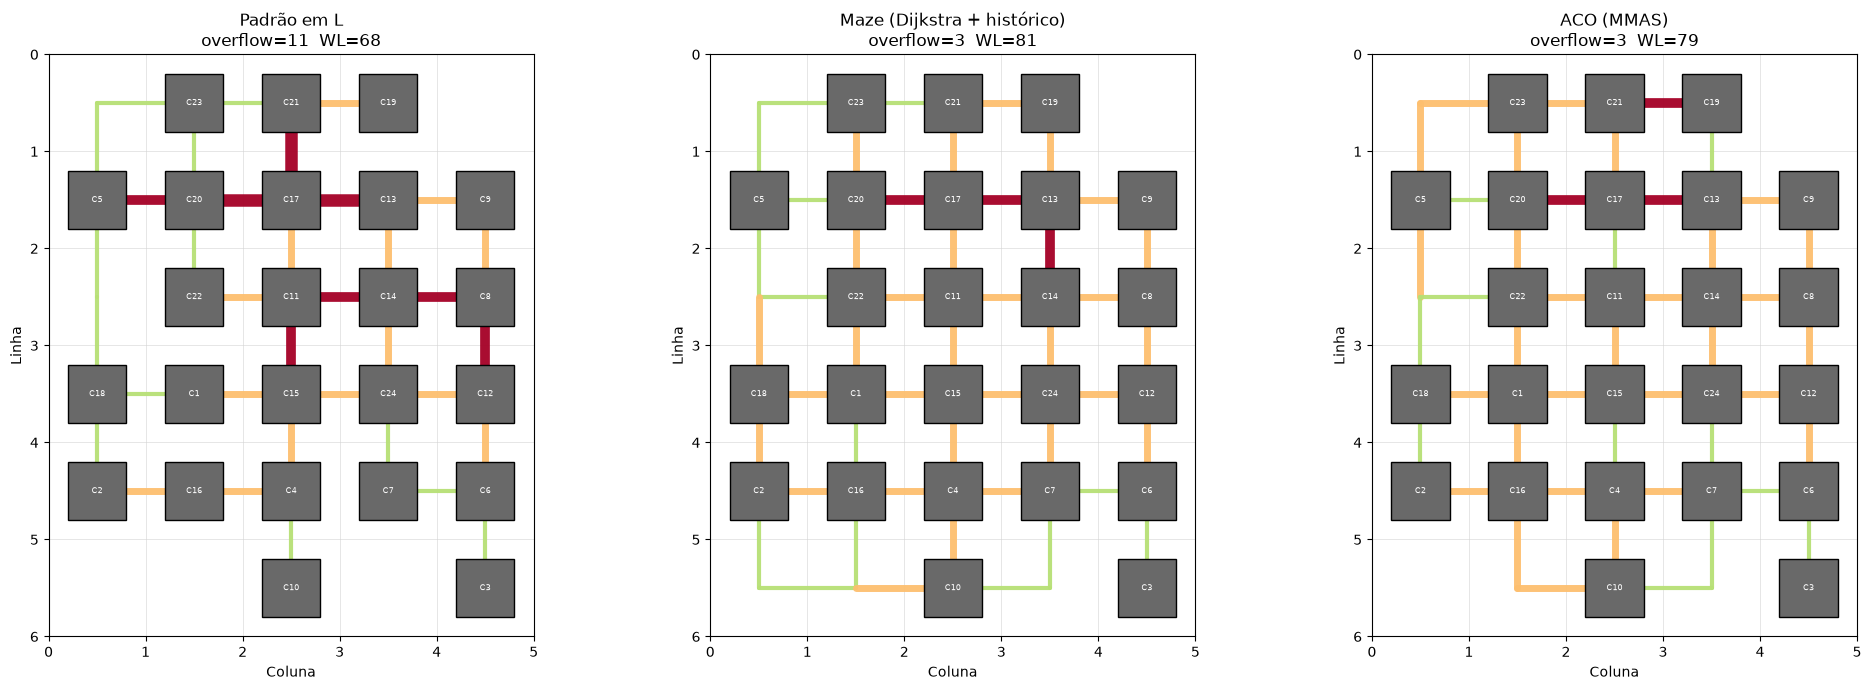

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (nome, r) in zip(axes, roteadores.items()):
    m = r.metricas()
    plotar_roteamento(
        df_componentes, grade, posicoes, r.uso, ax=ax,
        titulo=f"{nome}\noverflow={m['overflow']:.0f}  WL={m['wirelength']:.0f}",
        mostrar_colorbar=False,
    )
plt.tight_layout()
plt.show()

### 7.3 Uma rede em detalhe: a árvore de Steiner de cada método

Destacamos em azul a árvore da **maior rede** (tipicamente o clock). O método por padrões em L só conecta por formas em L;
o Maze constrói a árvore pelo caminho mais barato; o ACO amostra árvores com **pontos de Steiner** distribuídos conforme o feromônio e o congestionamento.

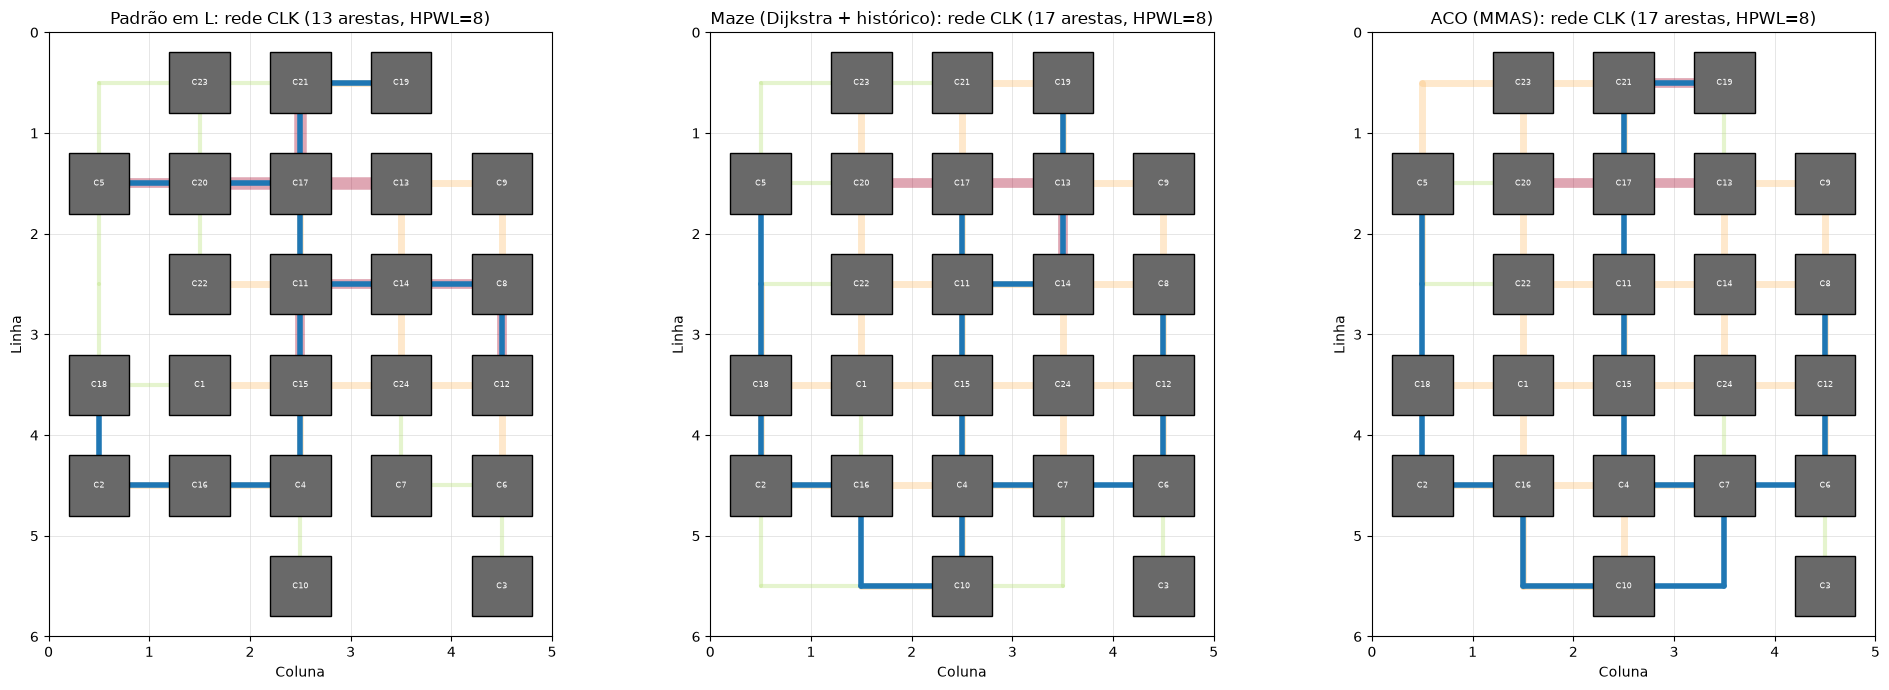

In [8]:
i_maior = int(np.argmax([len(p) for p in roteadores["ACO (MMAS)"].pinos]))
nome_maior = roteadores["ACO (MMAS)"].nomes[i_maior]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (nome, r) in zip(axes, roteadores.items()):
    plotar_roteamento(
        df_componentes, grade, posicoes, r.uso, rotas=r.rotas, destacar=i_maior, ax=ax,
        titulo=f"{nome}: rede {nome_maior} ({len(r.rotas[i_maior])} arestas, "
               f"HPWL={r.hpwl_rede[i_maior]})",
        mostrar_colorbar=False,
    )
plt.tight_layout()
plt.show()

### 7.4 Convergência

Evolução, por varredura de rip-up and reroute, do overflow total e do wirelength total da solução **corrente** (não da melhor).
Oscilações são esperadas: ao refazer redes, o algoritmo desloca o congestionamento de um lugar para outro.
O wirelength costuma **subir** depois da 1ª iteração: o roteador aceita desvios mais longos (troca comprimento por redução de overflow), e é por isso que o critério lexicográfico do problema prioriza o overflow.

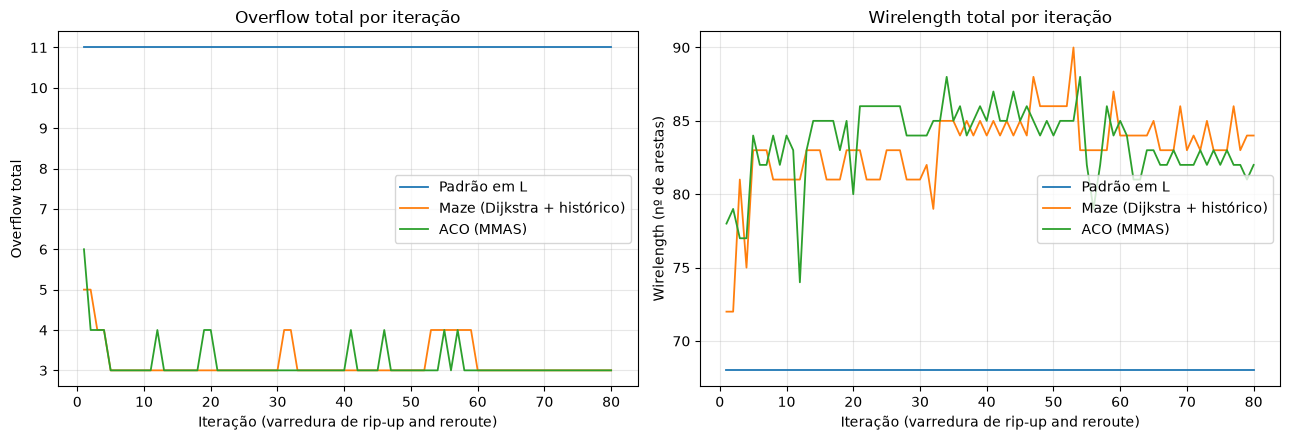

Padrão em L                    melhor (overflow, WL) = (11, 68) na iteração 1; 1ª iteração viável: nunca
Maze (Dijkstra + histórico)    melhor (overflow, WL) = (3, 81) na iteração 8; 1ª iteração viável: nunca
ACO (MMAS)                     melhor (overflow, WL) = (3, 79) na iteração 56; 1ª iteração viável: nunca


In [9]:
plotar_convergencia_roteamento(historicos)
plt.tight_layout()
plt.show()

for nome, h in historicos.items():
    viavel = h.primeira_iteracao_viavel
    print(f"{nome:30s} melhor (overflow, WL) = ({h.melhor_overflow:.0f}, {h.melhor_wirelength:.0f}) "
          f"na iteração {h.melhor_iteracao + 1}; 1ª iteração viável: "
          f"{'nunca' if viavel is None else viavel + 1}")

### 7.5 O que a colônia aprendeu: mapa de feromônio

O feromônio $\tau^{n}_e$ da colônia da maior rede ao final da execução. Arestas mais grossas e claras são as que a colônia
aprendeu a preferir; a árvore final aparece tracejada em vermelho. A escala de cor usa a **faixa observada** de $\tau$ (o depósito é no máximo $\mathrm{HPWL}_n/C(T)<1$, então o $\tau_{\max}$ nominal raramente é atingido). Os valores ficam sempre dentro de $[\tau_{\min},\tau_{\max}]$ (limites MMAS).

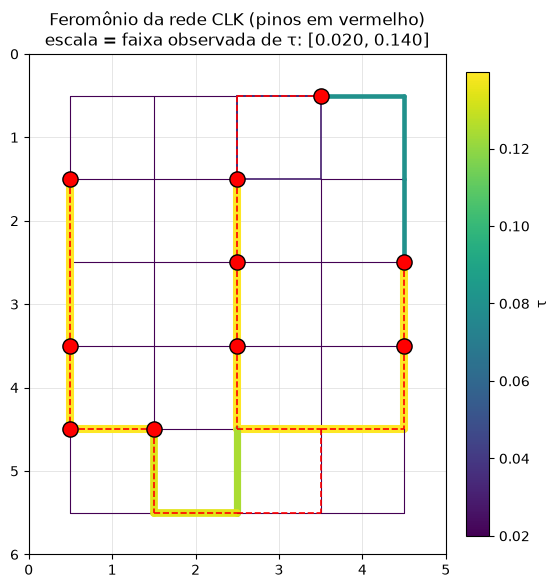

tau em [0.020, 0.140]  (tau_min=0.020, tau_max=1.000)


In [10]:
r_aco = roteadores["ACO (MMAS)"]
plotar_feromonio(r_aco, i_maior, df_componentes, posicoes)
plt.show()
print(f"tau em [{r_aco.tau[i_maior].min():.3f}, {r_aco.tau[i_maior].max():.3f}]  "
      f"(tau_min={r_aco.tau_min:.3f}, tau_max={r_aco.tau_max:.3f})")

## 8. Experimentos: comparação estatística e análise

### 8.1 Comparação com várias sementes

Os métodos são estocásticos (ordem das redes, formigas), então comparamos **10 sementes** por método.
Reportamos a média e o desvio de overflow e wirelength, a taxa de execuções viáveis, a razão WL/HPWL e o tempo.

In [11]:
SEMENTES = range(10)
df_cmp = comparar_metodos(grade, pinos, configs, n_iteracoes=N_ITER, sementes=SEMENTES)
resumo_principal = resumir_comparacao(df_cmp)
resumo_principal

,overflow_medio,overflow_dp,taxa_viavel,wl_medio,wl_dp,wl_sobre_hpwl,iter_1a_viavel,tempo_medio_s
metodo,,,,,,,,
Padrão em L,11.0,0.0,0.0,68.0,0.000,1.153,NaN,0.048
Maze (Dijkstra + histórico),3.0,0.0,0.0,80.1,1.972,1.358,NaN,0.038
ACO (MMAS),3.0,0.0,0.0,78.8,0.872,1.336,NaN,0.715


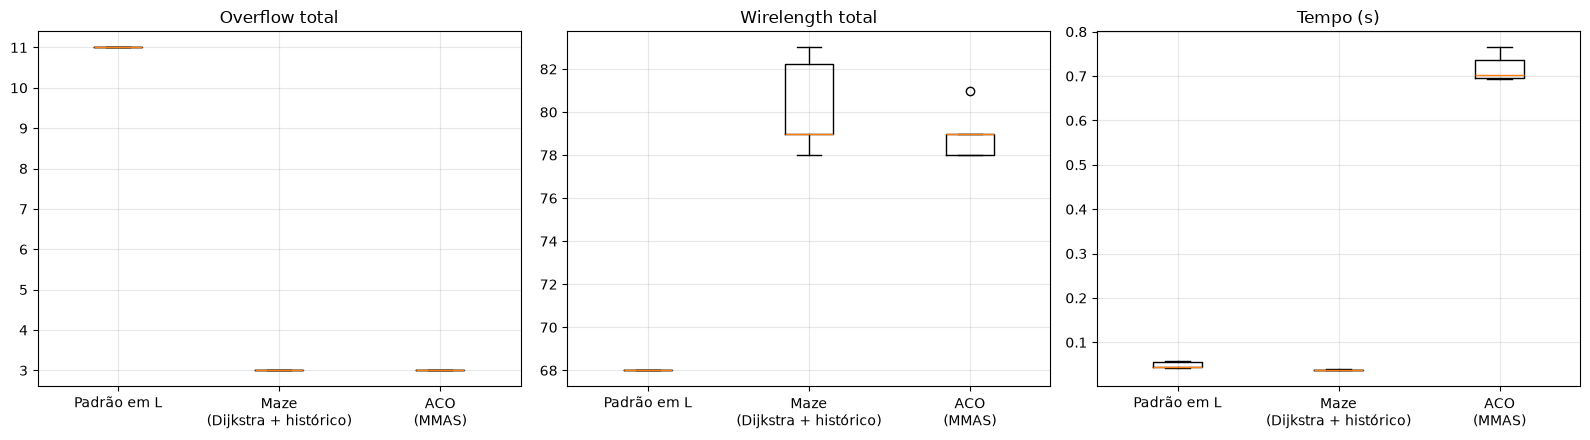

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ordem = list(configs.keys())
for ax, col, tit in zip(axes, ["overflow", "wirelength", "tempo_s"],
                        ["Overflow total", "Wirelength total", "Tempo (s)"]):
    dados = [df_cmp.loc[df_cmp.metodo == m, col].values for m in ordem]
    ax.boxplot(dados, tick_labels=[m.replace(" (", "\n(") for m in ordem])
    ax.set_title(tit)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8.2 Uma instância maior e mais congestionada

A instância do placement acima é pequena (dezenas de arestas): ela ajuda a **entender** o algoritmo, mas **discrimina pouco os métodos**.
Para um teste de escala, geramos uma instância sintética com **100 componentes e 140 redes** (maioria com 2 a 3 pinos e cauda
de redes grandes, com localidade entre os pinos), posicionada pelo mesmo SA. Os experimentos 8.3 a 8.5 usam essa instância.

In [13]:
df_comp_g, df_net_g = gerar_instancia_grande(n_componentes=100, n_redes=140, semente=11)
redes_g = construir_redes(df_comp_g, df_net_g)
nl_g, nc_g = dimensoes_grade_sugerida(len(df_comp_g), folga=1.25)

sa_g = SAPlacement(len(df_comp_g), redes_g, nl_g, nc_g, 500.0, 0.5, 0.93, 300, semente=3)
c0_g = sa_g.custo_atual
hist_g = sa_g.executar()
pos_g = hist_g.melhor_posicoes_global
print(f"Instância grande: {len(df_comp_g)} componentes, {len(redes_g)} redes, grade {nl_g}x{nc_g}")
print(f"HPWL: {c0_g:.0f} (aleatório) -> {hist_g.melhor_custo_global:.0f} (SA)")

grade_g = GradeRoteamento(nl_g, nc_g, capacidade=5)
pinos_g = construir_pinos_das_redes(redes_g, pos_g, grade_g)
print(f"Soma dos HPWL (limite inferior de WL): {hpwl_total(pinos_g, grade_g)}")
print(f"Arestas: {grade_g.n_arestas}  |  densidade de demanda mínima: "
      f"{hpwl_total(pinos_g, grade_g) / grade_g.n_arestas:.2f} fios por aresta (em média)")

Instância grande: 100 componentes, 140 redes, grade 12x11
HPWL: 1373 (aleatório) -> 672 (SA)
Soma dos HPWL (limite inferior de WL): 672
Arestas: 241  |  densidade de demanda mínima: 2.79 fios por aresta (em média)


### 8.3 Varredura de capacidade: do regime apertado ao folgado

A **capacidade** define a dificuldade. A demanda média mínima (HPWL / nº de arestas) indica a partir de que capacidade a
instância **pode** ser viável, mas a demanda é espacialmente irregular (o centro do chip é muito mais disputado). Variamos a capacidade e medimos, para cada método,
overflow e wirelength (média e desvio em 3 sementes, 40 iterações). A linha tracejada é o **limite inferior de overflow** por corte.

In [14]:
CAPS = [4, 5, 6, 7, 8]
SEM_G = range(3)
metodos_g = {
    "Padrão em L": (RoteadorPadrao, {}),
    "Maze": (RoteadorMaze, {}),
    "ACO": (RoteadorACO, dict(n_formigas=6)),
}

linhas_cap, lbs = [], {}
for cap in CAPS:
    gc = GradeRoteamento(nl_g, nc_g, capacidade=cap)
    pc = construir_pinos_das_redes(redes_g, pos_g, gc)
    lbs[cap] = limite_inferior_overflow(pc, gc)
    d = comparar_metodos(gc, pc, metodos_g, n_iteracoes=40, sementes=SEM_G)
    d["capacidade"] = cap
    linhas_cap.append(d)
df_cap = pd.concat(linhas_cap, ignore_index=True)

tab = (df_cap.groupby(["capacidade", "metodo"], sort=False)
       .agg(overflow=("overflow", "mean"), of_dp=("overflow", "std"),
            wirelength=("wirelength", "mean"), wl_dp=("wirelength", "std"),
            tempo_s=("tempo_s", "mean"))
       .round(2))
tab["LB overflow"] = [lbs[c] for c, _ in tab.index]
tab

overflow  of_dp  wirelength  wl_dp  tempo_s  \
capacidade metodo                                                     
4          Padrão em L    143.33   2.08      760.00   1.73     0.18   
           Maze            88.67   0.58      887.33   5.86     0.22   
           ACO             91.00   1.73      898.33   8.14     3.31   
5          Padrão em L     58.67   0.58      761.67   1.53     0.16   
           Maze            12.33   2.08      883.00   5.00     0.22   
           ACO             12.00   1.73      905.00  14.18     2.92   
6          Padrão em L     11.67   0.58      763.00   0.00     0.16   
           Maze             0.00   0.00      807.67  13.61     0.20   
           ACO              0.00   0.00      812.33  19.63     2.14   
7          Padrão em L      1.00   0.00      759.33   1.53     0.16   
           Maze             0.00   0.00      757.67   1.53     0.21   
           ACO              0.00   0.00      755.67   5.13     2.03   
8          Padrão em L      0.00   0.00      758.33   0.58     0.15   
           Maze             0.00   0.00      757.00   2.00     0.21   
           ACO              0.00   0.00      746.33   2.52     2.01   

                        LB overflow  
capacidade metodo                    
4          Padrão em L         25.0  
           Maze                25.0  
           ACO                 25.0  
5          Padrão em L          0.0  
           Maze                 0.0  
           ACO                  0.0  
6          Padrão em L          0.0  
           Maze                 0.0  
           ACO                  0.0  
7          Padrão em L          0.0  
           Maze                 0.0  
           ACO                  0.0  
8          Padrão em L          0.0  
           Maze                 0.0  
           ACO                  0.0

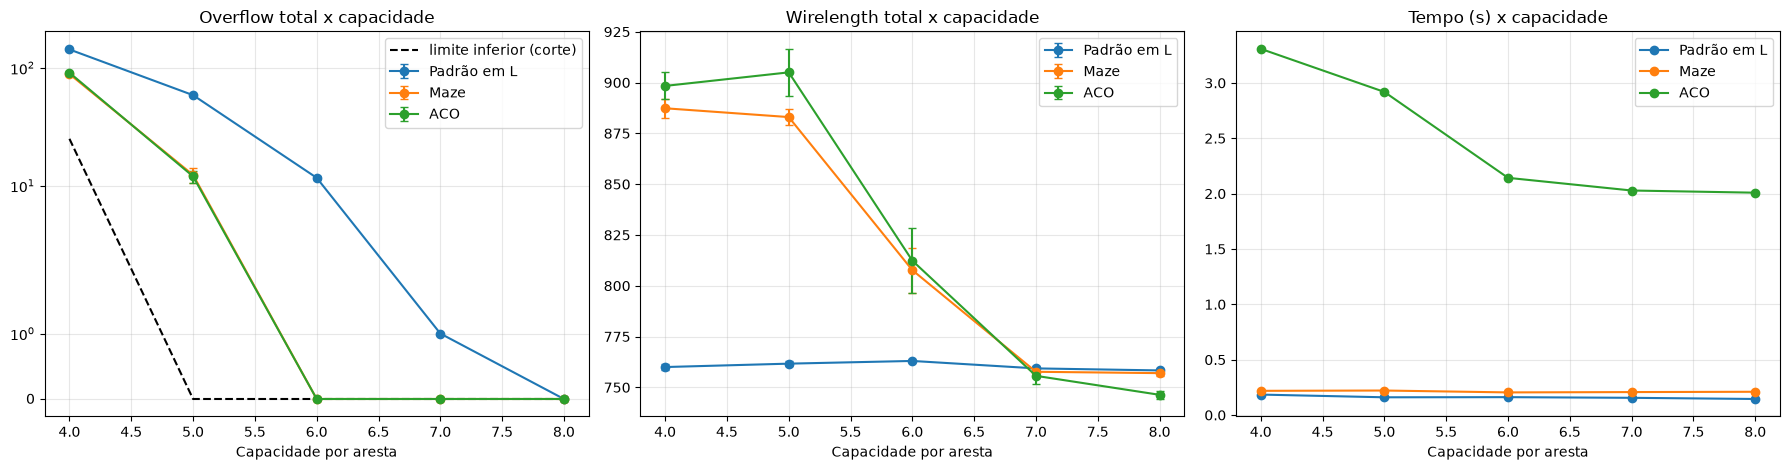

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for m in metodos_g:
    sub = df_cap[df_cap.metodo == m].groupby("capacidade")
    mu, sd = sub["overflow"].mean(), sub["overflow"].std(ddof=0)
    axes[0].errorbar(mu.index, mu.values, yerr=sd.values, marker="o", capsize=3, label=m)
    mu, sd = sub["wirelength"].mean(), sub["wirelength"].std(ddof=0)
    axes[1].errorbar(mu.index, mu.values, yerr=sd.values, marker="o", capsize=3, label=m)
    axes[2].plot(sub["tempo_s"].mean().index, sub["tempo_s"].mean().values, marker="o", label=m)
axes[0].plot(list(lbs.keys()), list(lbs.values()), "k--", label="limite inferior (corte)")
axes[0].set_yscale("symlog")
axes[0].set_title("Overflow total x capacidade")
axes[1].set_title("Wirelength total x capacidade")
axes[2].set_title("Tempo (s) x capacidade")
for ax in axes:
    ax.set_xlabel("Capacidade por aresta")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 8.4 Sensibilidade aos hiperparâmetros do ACO

Variamos um hiperparâmetro de cada vez em torno da configuração padrão, no regime **apertado** da instância grande
(capacidade 5, onde ainda há overflow e portanto há o que otimizar), com 3 sementes e 30 iterações.

In [16]:
gs = GradeRoteamento(nl_g, nc_g, capacidade=5)
ps = construir_pinos_das_redes(redes_g, pos_g, gs)

base = dict(n_formigas=6)
variacoes = {
    "padrão (K=6, α=1, β=2, ρ=0,1)": {},
    "ρ = 0,02": dict(rho=0.02),
    "ρ = 0,3": dict(rho=0.3),
    "β = 1": dict(beta=1.0),
    "β = 4": dict(beta=4.0),
    "α = 0 (sem feromônio)": dict(alpha=0.0),
    "α = 2": dict(alpha=2.0),
    "K = 2 formigas": dict(n_formigas=2),
    "K = 12 formigas": dict(n_formigas=12),
}
metodos_s = {nome: (RoteadorACO, {**base, **kw}) for nome, kw in variacoes.items()}
df_sens = comparar_metodos(gs, ps, metodos_s, n_iteracoes=30, sementes=range(3))
resumir_comparacao(df_sens)[["overflow_medio", "overflow_dp", "wl_medio", "wl_dp", "tempo_medio_s"]]

,overflow_medio,overflow_dp,wl_medio,wl_dp,tempo_medio_s
metodo,,,,,
"padrão (K=6, α=1, β=2, ρ=0,1)",13.000,1.633,907.000,12.832,2.213
"ρ = 0,02",14.000,1.414,912.667,2.625,2.264
"ρ = 0,3",11.667,2.494,895.333,4.643,1.993
β = 1,16.000,2.160,926.667,19.189,1.901
β = 4,14.333,1.700,904.667,2.625,2.440
α = 0 (sem feromônio),13.333,0.471,902.667,6.128,2.335
α = 2,14.333,1.247,904.333,7.409,2.126
K = 2 formigas,13.000,1.633,936.333,9.877,0.791
K = 12 formigas,13.000,0.000,920.000,14.720,4.101


O caso **α = 0** é um *controle*: sem feromônio, a formiga usa só a informação heurística (custo + direção); a diferença para o padrão
mede quanto o **aprendizado por feromônio** contribui. Compare a diferença com o desvio entre sementes: se for menor, nesse regime o
ganho do ACO vem mais da **amostragem estocástica de várias árvores** do que da memória do feromônio. Com apenas 3 sementes, diferenças pequenas
não são conclusivas. O papel do feromônio no **refinamento de wirelength** (regime sem congestionamento) é testado separadamente em 8.5.

### 8.5 Qualidade da árvore de Steiner isolada (sem congestionamento) e o papel do feromônio

Para isolar a **qualidade de construção de árvores** (o cenário em que o ACO é estudado na literatura de RSMT), usamos uma capacidade tão alta que não há
congestionamento e olhamos apenas para a razão WL/HPWL (quanto mais perto de 1, melhor). Os baselines **Maze** (Prim sobre o grafo) e
**Padrão em L** são determinísticos: constroem a árvore uma vez e não melhoram mais. O ACO, ao contrário, **aprende ao longo das iterações**, então a comparação
justa é uma **curva WL/HPWL × iteração**. Incluímos o **controle $\alpha=0$** (formigas sem feromônio, só com custo e direção): ele separa o ganho
da *memória coletiva* do ganho do mero *sorteio de várias árvores com elitismo*.

In [17]:
gl = GradeRoteamento(nl_g, nc_g, capacidade=1000)   # sem congestionamento
pl = construir_pinos_das_redes(redes_g, pos_g, gl)
lb_l = hpwl_total(pl, gl)

N_IT_STEINER, SEM_STEINER = 60, range(3)

def trajetoria(classe, **kw):
    # WL/HPWL da solução corrente a cada iteração, por semente: matriz (sementes x iterações)
    trajs = []
    for s in SEM_STEINER:
        _, h = executar_metodo(classe, gl, pl, n_iteracoes=N_IT_STEINER, semente=s, **kw)
        trajs.append(np.array(h.wirelength) / lb_l)
    return np.array(trajs)

ref = {
    "Maze (Prim/Dijkstra)": trajetoria(RoteadorMaze)[:, -1].mean(),
    "Padrão em L": trajetoria(RoteadorPadrao)[:, -1].mean(),
}
curvas = {
    "ACO K=2": trajetoria(RoteadorACO, n_formigas=2),
    "ACO K=6": trajetoria(RoteadorACO, n_formigas=6),
    "ACO K=16": trajetoria(RoteadorACO, n_formigas=16),
    "ACO K=6, α=0 (controle: sem feromônio)": trajetoria(RoteadorACO, n_formigas=6, alpha=0.0),
}
print(f"Limite inferior (soma dos HPWL) = {lb_l}")

Limite inferior (soma dos HPWL) = 672


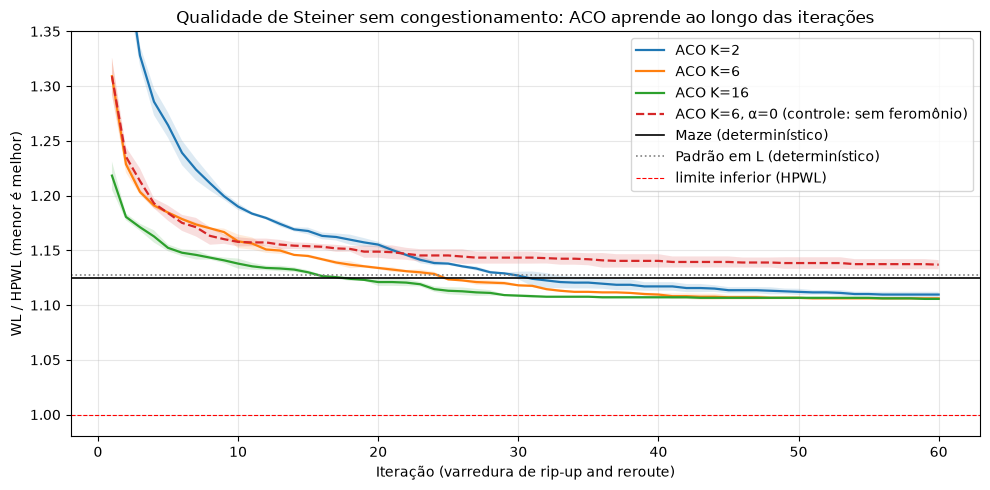

Referências: Maze = 1.125 | Padrão em L = 1.127


,WL/HPWL (iter. 1),WL/HPWL (final),dp final,1ª iteração abaixo do Maze
variante,,,,
ACO K=2,1.594,1.110,0.0025,31
ACO K=6,1.309,1.106,0.0007,25
ACO K=16,1.218,1.106,0.0000,18
"ACO K=6, α=0 (controle: sem feromônio)",1.309,1.137,0.0042,nunca


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
its = np.arange(1, N_IT_STEINER + 1)
for nome, T in curvas.items():
    mu, sd = T.mean(0), T.std(0)
    ls = "--" if "α=0" in nome else "-"
    ax.plot(its, mu, ls, label=nome, linewidth=1.6)
    ax.fill_between(its, mu - sd, mu + sd, alpha=0.15)
ax.axhline(ref["Maze (Prim/Dijkstra)"], color="k", linewidth=1.2, label="Maze (determinístico)")
ax.axhline(ref["Padrão em L"], color="gray", linestyle=":", linewidth=1.2, label="Padrão em L (determinístico)")
ax.axhline(1.0, color="red", linestyle="--", linewidth=0.8, label="limite inferior (HPWL)")
ax.set_ylim(0.98, 1.35)
ax.set_xlabel("Iteração (varredura de rip-up and reroute)")
ax.set_ylabel("WL / HPWL (menor é melhor)")
ax.set_title("Qualidade de Steiner sem congestionamento: ACO aprende ao longo das iterações")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# tabela-resumo: valor final e iteração em que cada curva passa a ficar abaixo do Maze
maze = ref["Maze (Prim/Dijkstra)"]
linhas = []
for nome, T in curvas.items():
    mu = T.mean(0)
    abaixo = np.where(mu < maze)[0]
    linhas.append({
        "variante": nome,
        "WL/HPWL (iter. 1)": round(mu[0], 3),
        "WL/HPWL (final)": round(mu[-1], 3),
        "dp final": round(T[:, -1].std(), 4),
        "1ª iteração abaixo do Maze": int(abaixo[0] + 1) if len(abaixo) else "nunca",
    })
print(f"Referências: Maze = {maze:.3f} | Padrão em L = {ref['Padrão em L']:.3f}")
pd.DataFrame(linhas).set_index("variante")

## 9. Conclusão

A célula abaixo compara ACO e Maze (o baseline forte) com base nas tabelas calculadas acima, com um critério simples:
uma diferença só é considerada **real** quando supera o desvio-padrão entre sementes. É um critério grosseiro, e com 3 sementes (8.3) deve ser lido com cautela.

In [19]:
def veredito(resumo, a="ACO (MMAS)", b="Maze (Dijkstra + histórico)"):
    ra, rb = resumo.loc[a], resumo.loc[b]
    def cmp(nome, va, vb, dp, menor_melhor=True):
        dif = va - vb
        if abs(dif) <= max(dp, 1e-9):
            return f"{nome}: sem diferença clara ({va:.2f} vs {vb:.2f}, dentro de 1 desvio-padrão)"
        melhor = (dif < 0) == menor_melhor
        return f"{nome}: ACO {'melhor' if melhor else 'pior'} ({va:.2f} vs {vb:.2f})"
    print(cmp("overflow", ra.overflow_medio, rb.overflow_medio, max(ra.overflow_dp, rb.overflow_dp)))
    print(cmp("wirelength", ra.wl_medio, rb.wl_medio, max(ra.wl_dp, rb.wl_dp)))
    print(f"tempo: ACO leva {ra.tempo_medio_s / max(rb.tempo_medio_s, 1e-9):.1f}x o tempo do Maze")

print("== Instância do placement (8.1) ==")
veredito(resumo_principal)

print("\n== Instância grande, por capacidade (8.3) ==")
for cap in CAPS:
    sub = df_cap[df_cap.capacidade == cap]
    r = resumir_comparacao(sub).rename(index={"ACO": "ACO (MMAS)", "Maze": "Maze (Dijkstra + histórico)"})
    print(f"-- capacidade {cap} (limite inferior de overflow = {lbs[cap]:.0f})")
    veredito(r)

== Instância do placement (8.1) ==
overflow: sem diferença clara (3.00 vs 3.00, dentro de 1 desvio-padrão)
wirelength: sem diferença clara (78.80 vs 80.10, dentro de 1 desvio-padrão)
tempo: ACO leva 18.8x o tempo do Maze

== Instância grande, por capacidade (8.3) ==
-- capacidade 4 (limite inferior de overflow = 25)
overflow: ACO pior (91.00 vs 88.67)
wirelength: ACO pior (898.33 vs 887.33)
tempo: ACO leva 15.1x o tempo do Maze
-- capacidade 5 (limite inferior de overflow = 0)
overflow: sem diferença clara (12.00 vs 12.33, dentro de 1 desvio-padrão)
wirelength: ACO pior (905.00 vs 883.00)
tempo: ACO leva 13.1x o tempo do Maze
-- capacidade 6 (limite inferior de overflow = 0)
overflow: sem diferença clara (0.00 vs 0.00, dentro de 1 desvio-padrão)
wirelength: sem diferença clara (812.33 vs 807.67, dentro de 1 desvio-padrão)
tempo: ACO leva 10.5x o tempo do Maze
-- capacidade 7 (limite inferior de overflow = 0)
overflow: sem diferença clara (0.00 vs 0.00, dentro de 1 desvio-padrão)
wirele

#### 9.1 Análise

#### Interpretação dos resultados da seção 8.5 (qualidade de Steiner sem congestionamento)

Sem congestionamento, o que separa os métodos é só o wirelength. Os baselines determinísticos fecham a árvore de uma vez (Maze: WL/HPWL = 1,125; Padrão em L: 1,127), enquanto o ACO aprende ao longo das iterações:

| Variante | WL/HPWL (iter. 1) | WL/HPWL (final) | 1ª iteração abaixo do Maze |
|---|---|---|---|
| ACO, $K=2$ | 1,594 | 1,110 | 31 |
| ACO, $K=6$ | 1,309 | 1,106 | 25 |
| ACO, $K=16$ | 1,218 | 1,106 | 18 |
| ACO, $K=6$, $\alpha=0$ (sem feromônio) | 1,309 | 1,137 | nunca |

- **Começa pior, termina melhor.** Na 1ª iteração o feromônio ainda é uniforme, e as formigas só contam com custo e direção, então a árvore é pior que a dos baselines. Com iterações suficientes (18 a 31) o ACO passa o Maze e estabiliza em ≈ 1,106, ou seja, **≈ 1,7% menos fio** que o Maze. Isso é coerente com 8.3, onde o ACO só se destaca em wirelength na capacidade folgada (8); com capacidade apertada (4 e 5) ele empata ou perde.
- **O ganho vem do feromônio, e não só do sorteio de árvores.** O controle $\alpha=0$ usa as mesmas formigas e o mesmo elitismo, mas termina em 1,137, **pior que o Maze**. A diferença para o ACO completo (≈ 0,03) é muito maior que o desvio entre sementes (≤ 0,004). A memória coletiva é o que de fato refina as árvores. Uma explicação plausível, mas não testada aqui, é que o Maze fixa uma única ordem gulosa de conexão dos pinos, enquanto o ACO explora ordens e caminhos diferentes e reforça os melhores.
- **Mais formigas aceleram, mas não melhoram o resultado final.** Subir $K$ de 2 para 16 antecipa o cruzamento com o Maze (iteração 31 → 18). O valor final é praticamente o mesmo para $K=6$ e $K=16$ (1,106), e só $K=2$ fica um pouco acima (1,110). Como o custo por iteração cresce com $K$, valores intermediários ($K\approx 6$) parecem um bom compromisso nesta instância.
- **Custo.** O ganho de ≈ 1,7% custa pelo menos uma ordem de grandeza em tempo (ver 8.3), pois o Maze já converge em poucas iterações. Em um fluxo real, isso só se justifica para refinar redes críticas ou grandes, e não para todas.

**Ressalvas.** Resultado de **uma instância sintética**, 3 sementes e **sem congestionamento**. O limite HPWL não é atingível para redes multi-pino, então o gap restante (≈ 10,6% sobre 1,0) não é todo folga. A conclusão de que o ACO supera o Maze **depende do orçamento de iterações**: com poucas iterações o resultado se inverte.



### 9.2 Discussão

Hipóteses razoáveis a partir da estrutura do problema. Os experimentos acima permitem **verificá-las (ou refutá-las) para a *sua* instância**, conforme os dados variam, e a leitura automática de 9.1 diz o que de fato ocorreu:

- **Regime muito apertado** (capacidade abaixo da demanda): nenhum método fica viável, e o overflow restante é dominado por gargalos do *placement*,
  que o roteamento não pode corrigir. Conclusão prática: **roteabilidade é decidida em grande parte no placement**, e uma
  função de custo do SA que considere congestionamento (e não só HPWL) é o caminho natural.
- **Regime intermediário** (onde o RRR consegue fechar o overflow): o ganho de um construtor estocástico sobre o Maze é, no
  máximo, modesto, pois o custo histórico do RRR já resolve boa parte do congestionamento. Verifique em 8.3 se a diferença supera o desvio entre sementes.
- **Regime folgado** (sem overflow para ninguém): o que diferencia os métodos é o **wirelength**. Os baselines determinísticos constroem a árvore uma vez; o ACO
  começa pior (poucas informações no feromônio) mas **melhora a cada iteração**. A curva de 8.5 mostra se, e depois de quantas iterações, ele supera o Maze, e
  o controle $\alpha=0$ mostra quanto desse ganho se deve ao feromônio. Atenção: um orçamento de iterações pequeno **favorece os baselines** e pode levar à conclusão errada de que o ACO é pior.
- **Custo**: o ACO gera $K$ árvores por rede por iteração e é, por construção, várias vezes mais lento que o Maze nesta implementação
  em Python. Em roteadores de produção essa diferença é mitigada por paralelismo (as formigas são independentes), mas isso não foi explorado aqui.
- **Feromônio**: o controle `α = 0` aparece em dois regimes: em 8.4 (congestionado, overflow e wirelength) e em 8.5 (sem congestionamento, curva de WL/HPWL).
  Compare os dois: o aprendizado pode ser decisivo em um regime e irrelevante em outro.

### 9.3 Limitações deste estudo

- Modelo **2D** sem vias, camadas, obstáculos reais nem timing (seção 2.5).
- Baselines **reimplementados e simplificados**: não são CUGR, NTHU-Route 2.0 nem o `grt` do OpenROAD.
- Instâncias **sintéticas e pequenas** (a do placement com poucas dezenas de arestas; a grande com 241 arestas). Os resultados indicam tendências, e não substituem benchmarks ISPD.
- Não há garantia de otimalidade, e o limite inferior de overflow por corte é **folgado**: um valor zero não prova que a instância é viável.

### 9.4 Próximos passos

1. **Benchmarks reais**: ler as instâncias ISPD 2007/2008 e comparar com NTHU-Route 2.0, CUGR e o `grt` do OpenROAD (baselines externos).
2. **Topologia inicial com FLUTE** e ACO apenas para o refinamento (híbrido, como fazem os roteadores modernos).
3. **Roteamento 3D** com camadas, direções preferenciais e custo/capacidade de vias.
4. **Formigas em paralelo** (multiprocessing ou GPU) para reduzir o custo de tempo.
5. **Co-otimização placement × roteamento**: usar o congestionamento estimado como termo do custo do SA, fechando o ciclo entre os dois notebooks.
6. **Redes críticas de timing**: incluir atraso (por exemplo, Elmore) em $\eta$ e em $C(T)$.

---

## Referências

- Albrecht, C. *Global routing by new approximation algorithms for multicommodity flow.* IEEE TCAD, 2001.
- Chang, Y.-J.; Lee, Y.-T.; Gao, J.-R.; Wu, P.-C.; Wang, T.-C. *NTHU-Route 2.0: a robust global router for modern designs.* IEEE TCAD, 2010.
- Cho, M.; Lu, K.; Yuan, K.; Pan, D. Z. *BoxRouter 2.0: architecture and implementation of a hybrid and robust global router.* ICCAD, 2007.
- Chu, C.; Wong, Y.-C. *FLUTE: fast lookup table based rectilinear Steiner minimal tree algorithm for VLSI design.* IEEE TCAD, 2008.
- Dorigo, M.; Maniezzo, V.; Colorni, A. *The Ant System: optimization by a colony of cooperating agents.* IEEE Trans. SMC-B, 26(1), 1996.
- Garey, M. R.; Johnson, D. S. *The rectilinear Steiner tree problem is NP-complete.* SIAM J. Appl. Math., 1977.
- Han, Y.; Ancajas, D. M.; Chakraborty, K.; Roy, S. *Exploring high-throughput computing paradigm for global routing.* IEEE TVLSI, 22(1), 155–167, 2014.
- Hanan, M. *On Steiner's problem with rectilinear distance.* SIAM J. Appl. Math., 1966.
- Hu, Y.; Jing, T.; Feng, Z.; Hong, X.; Hu, X.; Yan, G. *ACO-Steiner: ant colony optimization based rectilinear Steiner minimal tree algorithm.* J. Comput. Sci. Technol., 21, 147–152, 2006.
- Jing, T.; Hong, X.; Xu, J.; Bao, H.; Cheng, C.-K.; Gu, J. *UTACO: a unified timing and congestion optimization algorithm for standard cell global routing.* IEEE TCAD, 23(3), 358–365, 2004.
- Karp, R. M. *Reducibility among combinatorial problems.* 1972.
- Kastner, R.; Bozorgzadeh, E.; Sarrafzadeh, M. *Pattern routing: use and theory for increasing predictability and avoiding coupling.* IEEE TCAD, 2002.
- Liu, S.; Liao, P.; Zhang, R.; Chen, Z.; Lv, W.; Lin, Y.; Yu, B. *FastGR: global routing on CPU-GPU with heterogeneous task graph scheduler.* IEEE TCAD, 42(7), 2023.
- Liu, J.; Pui, C.-W.; Wang, F.; Young, E. F. Y. *CUGR: detailed-routability-driven 3D global routing with probabilistic resource model.* DAC, 2020.
- Liu, W.-H.; Kao, W.-C.; Li, Y.-L.; Chao, K.-Y. *NCTU-GR 2.0: multithreaded collision-aware global routing with bounded-length maze routing.* IEEE TCAD, 2013.
- McMurchie, L.; Ebeling, C. *PathFinder: a negotiation-based performance-driven router for FPGAs.* FPGA, 1995.
- Nam, G.-J.; Sze, C.; Yildiz, M. *The ISPD global routing benchmark suite.* ISPD, 2008.
- Pan, M.; Chu, C. *FastRoute: a step to integrate global routing into placement.* ICCAD, 2006. Xu, Y.; Zhang, Y.; Chu, C. *FastRoute 4.0: global router with efficient via minimization.* ASP-DAC, 2009.
- Liu, G. et al. *XGRouter: high-quality global router in X-architecture with particle swarm optimization.* (citado em levantamento sobre inteligência de enxame em roteamento VLSI).
- Stützle, T.; Hoos, H. H. *MAX–MIN Ant System.* Future Generation Computer Systems, 16(8), 2000.
- Takahashi, H.; Matsuyama, A. *An approximate solution for the Steiner problem in graphs.* Math. Japonica, 1980.
